In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

In [2]:
df = pd.read_csv('D:\\Semester 5\\ML\\244107020017_Machine_Learning\\JS06_Regresi\\dataset\\insurance.csv')

print("Ukuran dataset:", df.shape)
display(df.head())

Ukuran dataset: (1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [3]:
print("Informasi dataset:")
df.info()

print("\nStatistik deskriptif:")
display(df.describe())

print("\nJumlah missing value:")
print(df.isnull().sum())

print("\nJumlah data duplikat:", df.duplicated().sum())

Informasi dataset:
<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 94.5 KB

Statistik deskriptif:


,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010



Jumlah missing value:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Jumlah data duplikat: 1


In [4]:
X = df.drop(columns=['charges'])
y = df['charges']

numerical_features = [
    'age', 'bmi', 'children'
]

categorical_features = [
    'sex', 'smoker', 'region'
]

print("Fitur:", X.columns.tolist())
print("Target:", y.name)

Fitur: ['age', 'sex', 'bmi', 'children', 'smoker', 'region']
Target: charges


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Jumlah data latih:", len(X_train))
print("Jumlah data uji:", len(X_test))

Jumlah data latih: 1070
Jumlah data uji: 268


In [6]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'),
         categorical_features)
    ]
)

model_lr = Pipeline([
    ('preprocessing', preprocessor),
    ('regression', LinearRegression())
])

model_lr.fit(X_train, y_train)

y_pred_lr = model_lr.predict(X_test)

print("Model Multiple Linear Regression berhasil dilatih.")

Model Multiple Linear Regression berhasil dilatih.


In [7]:
def evaluasi_model(nama, y_true, y_pred):
    r2 = r2_score(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)

    print(f"\n{nama}")
    print(f"R-squared (R²): {r2:.4f}")
    print(f"MSE           : {mse:.2f}")
    print(f"MAE           : {mae:.2f}")

    return {
        'Model': nama,
        'R2': r2,
        'MSE': mse,
        'MAE': mae
    }

hasil_lr = evaluasi_model(
    'Multiple Linear Regression',
    y_test,
    y_pred_lr
)


Multiple Linear Regression
R-squared (R²): 0.7836
MSE           : 33596915.85
MAE           : 4181.19


In [8]:
model_svr = Pipeline([
    ('preprocessing', ColumnTransformer(
        transformers=[
            ('num', StandardScaler(), numerical_features),
            ('cat', OneHotEncoder(handle_unknown='ignore'),
             categorical_features)
        ]
    )),
    ('regression', SVR(kernel='rbf', C=100, epsilon=0.1))
])

model_svr.fit(X_train, y_train)

y_pred_svr = model_svr.predict(X_test)

hasil_svr = evaluasi_model(
    'Support Vector Regression (SVR)',
    y_test,
    y_pred_svr
)


Support Vector Regression (SVR)
R-squared (R²): 0.1369
MSE           : 133991319.54
MAE           : 5967.49


In [9]:
hasil = pd.DataFrame([hasil_lr, hasil_svr])

display(hasil.round(4))

terbaik = hasil.sort_values(
    by='MAE',
    ascending=True
).iloc[0]

print("Model dengan MAE terendah:", terbaik['Model'])

,Model,R2,MSE,MAE
0,Multiple Linear Regression,0.7836,3.359692e+07,4181.1945
1,Support Vector Regression (SVR),0.1369,1.339913e+08,5967.4931


Model dengan MAE terendah: Multiple Linear Regression


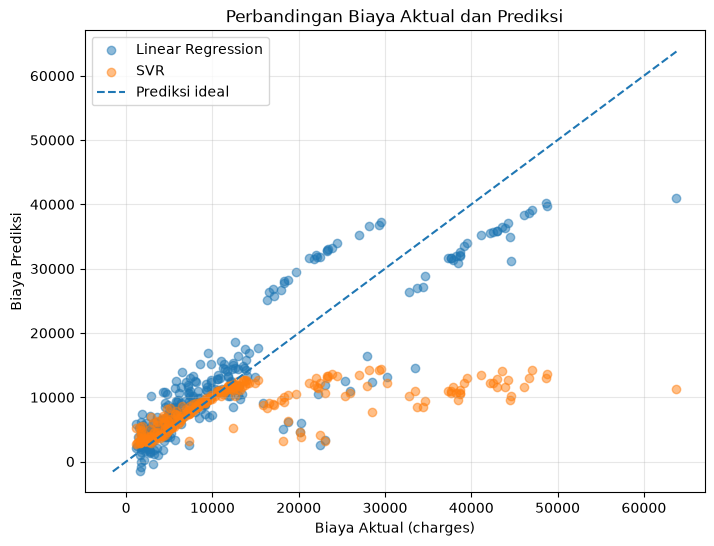

In [10]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred_lr, alpha=0.5, label='Linear Regression')
plt.scatter(y_test, y_pred_svr, alpha=0.5, label='SVR')

batas_min = min(y_test.min(), y_pred_lr.min(), y_pred_svr.min())
batas_max = max(y_test.max(), y_pred_lr.max(), y_pred_svr.max())

plt.plot(
    [batas_min, batas_max],
    [batas_min, batas_max],
    linestyle='--',
    label='Prediksi ideal'
)

plt.xlabel('Biaya Aktual (charges)')
plt.ylabel('Biaya Prediksi')
plt.title('Perbandingan Biaya Aktual dan Prediksi')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [11]:
perbandingan = pd.DataFrame({
    'Aktual': y_test.values,
    'Prediksi Linear Regression': y_pred_lr,
    'Prediksi SVR': y_pred_svr
})

display(perbandingan.head(10).round(2))

,Aktual,Prediksi Linear Regression,Prediksi SVR
0,9095.07,8969.55,9060.61
1,5272.18,7068.75,5314.12
2,29330.98,36858.41,14201.06
3,9301.89,9454.68,9369.71
4,33750.29,26973.17,8534.62
5,4536.26,10864.11,6769.46
6,2117.34,170.28,4127.85
7,14210.54,16903.45,12281.75
8,3732.63,1092.43,6086.20
9,10264.44,11218.34,10131.94
